# 🧠 Brain Tumor Classification from MRI Images
### *Image Processing & Computer Vision Interactive Project Walkthrough*

This notebook demonstrates every phase of the implemented pipeline:
1. **Classical Image Processing:** Extreme Contour Skull-Stripping, Homomorphic FFT Filtering, LAB-space CLAHE, Bilateral Denoising & Canny Edge Extraction
2. **Morphological Tumor Segmentation & Descriptors:** Otsu + Morphological Masking, GLCM Haralick & Shape Features
3. **Explainable AI (Grad-CAM) with Trained `ResNet18`:** Saliency overlays across all 4 MRI classes
4. **Quantitative Benchmark Comparison:** Classical ML (`SVM`, `Random Forest`) vs. `Custom CNN` vs. `ResNet18` (+ TTA)

In [1]:
import json
import sys
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision import transforms

# Resolve project root regardless of whether Jupyter starts in notebooks/ or project root
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import CLASSES, IMG_SIZE, DEVICE, DATA_RAW, CHECKPOINTS_DIR, REPORTS_DIR, OUTPUTS_DIR
from src.image_processing.skull_stripping import crop_brain_contour
from src.image_processing.enhancement import (
    apply_clahe,
    apply_bilateral_filter,
    apply_homomorphic_filter,
    extract_edge_map,
)
from src.image_processing.segmentation import (
    segment_tumor_region,
    extract_morphological_features,
    draw_segmentation_overlay,
)
from src.image_processing.feature_extraction import extract_glcm_features, extract_intensity_statistics
from src.models.custom_cnn import BrainTumorCNN
from src.models.transfer_models import build_transfer_model
from src.explainability.gradcam import GradCAM, overlay_cam_on_image

print(f"Project Root: {PROJECT_ROOT}")
print(f"Execution Device: {DEVICE}")

Project Root: C:\Users\adity\OneDrive\Desktop\Brain_tumon_classification\Brain_tumor_classification\Brain_tumor_classification
Execution Device: cpu


## 1. Classical Image Processing: Contour Crop, Homomorphic FFT, CLAHE, Edges & Segmentation
Loads a real glioma MRI scan from `data/raw/Testing/` (or falls back to the sanity-test sample) and visualizes each classical IPCV stage.

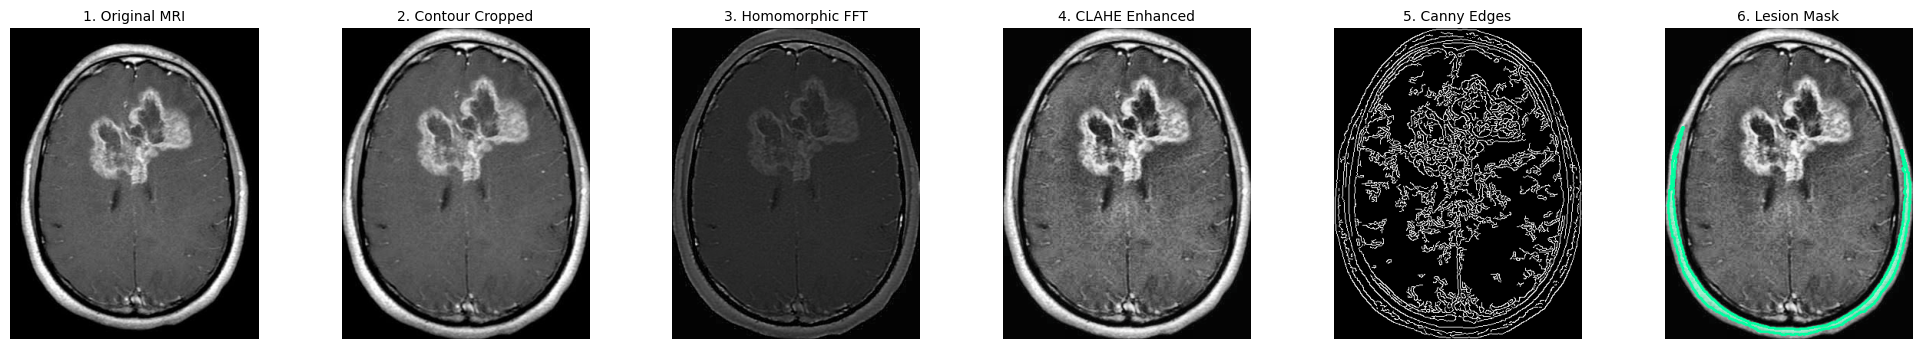

In [2]:
glioma_samples = sorted((DATA_RAW / "Testing" / "glioma").glob("*.jpg")) if (DATA_RAW / "Testing" / "glioma").exists() else []
sample_path = glioma_samples[0] if glioma_samples else (OUTPUTS_DIR / "test_run" / "sample_brain_mri.png")
raw_img = cv2.imread(str(sample_path))
assert raw_img is not None, f"Could not load {sample_path}"

cropped_img = crop_brain_contour(raw_img)
homo_img = apply_homomorphic_filter(cropped_img, color_space="BGR")
clahe_img = apply_clahe(cropped_img, clip_limit=2.0, color_space="BGR")
edge_map = extract_edge_map(clahe_img, method="canny", color_space="BGR")
seg_mask = segment_tumor_region(clahe_img, is_rgb=False)
seg_overlay_rgb = draw_segmentation_overlay(clahe_img, seg_mask, is_rgb=False)

fig, axes = plt.subplots(1, 6, figsize=(20, 3.6))
stages = [
    ("1. Original MRI", cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)),
    ("2. Contour Cropped", cv2.cvtColor(cropped_img, cv2.COLOR_BGR2RGB)),
    ("3. Homomorphic FFT", cv2.cvtColor(homo_img, cv2.COLOR_BGR2RGB)),
    ("4. CLAHE Enhanced", cv2.cvtColor(clahe_img, cv2.COLOR_BGR2RGB)),
    ("5. Canny Edges", edge_map),
    ("6. Lesion Mask", seg_overlay_rgb),
]
for ax, (title, vis) in zip(axes, stages):
    ax.imshow(vis, cmap="gray" if vis.ndim == 2 else None)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Handcrafted Texture, Intensity & Morphological Descriptors
Combines GLCM Haralick texture, intensity moments, and segmented lesion shape descriptors.

In [3]:
glcm_metrics = extract_glcm_features(clahe_img)
intensity_metrics = extract_intensity_statistics(clahe_img)
morph_metrics = extract_morphological_features(seg_mask)
combined = {**glcm_metrics, **intensity_metrics, **morph_metrics}
pd.DataFrame([{"Descriptor": k, "Value": round(v, 4)} for k, v in combined.items()])

,Descriptor,Value
0,contrast,753.2849
1,dissimilarity,15.5578
2,homogeneity,0.2391
3,energy,0.1443
4,correlation,0.9019
5,ASM,0.0208
6,mean_intensity,87.1140
7,std_intensity,62.1136
8,skewness,0.4401
9,kurtosis,-0.1836


## 3. Trained `ResNet18` Inference & Grad-CAM Across All 4 Classes
Loads `models_checkpoints/resnet18_best.pth` (if available) and visualizes predictions + Grad-CAM saliency overlays on one held-out test MRI per class.

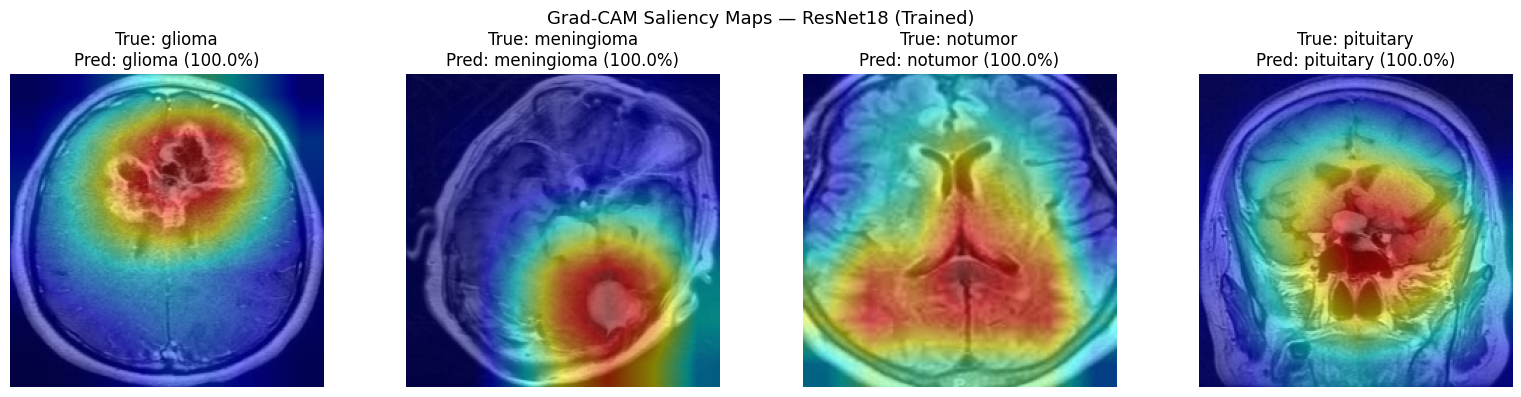

In [4]:
resnet_ckpt = CHECKPOINTS_DIR / "resnet18_best.pth"
if resnet_ckpt.exists():
    model = build_transfer_model("resnet18", num_classes=len(CLASSES), pretrained=False)
    model.load_state_dict(torch.load(resnet_ckpt, map_location=DEVICE)["model_state_dict"])
    model_label = "ResNet18 (Trained)"
else:
    model = BrainTumorCNN(num_classes=len(CLASSES))
    model_label = "Custom CNN (Untrained)"

model = model.to(DEVICE).eval()
infer_tf = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

fig, axes = plt.subplots(1, len(CLASSES), figsize=(16, 4))
cam_gen = GradCAM(model, model.target_gradcam_layer)
try:
    for ax, cls_name in zip(axes, CLASSES):
        cls_files = sorted((DATA_RAW / "Testing" / cls_name).glob("*.jpg")) if (DATA_RAW / "Testing" / cls_name).exists() else []
        img_path = cls_files[0] if cls_files else sample_path
        img_bgr = cv2.imread(str(img_path))
        proc_bgr = cv2.resize(apply_clahe(crop_brain_contour(img_bgr), clip_limit=2.0, color_space="BGR"), IMG_SIZE)
        proc_rgb = cv2.cvtColor(proc_bgr, cv2.COLOR_BGR2RGB)
        tensor = infer_tf(Image.fromarray(proc_rgb)).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            probs = torch.softmax(model(tensor), dim=1).squeeze(0).cpu().numpy()
        pred_idx = int(np.argmax(probs))
        cam = cam_gen.generate_heatmap(tensor, target_class=pred_idx)
        overlay = overlay_cam_on_image(proc_rgb, cam, is_rgb=True)
        ax.imshow(overlay)
        ax.set_title(f"True: {cls_name}\nPred: {CLASSES[pred_idx]} ({probs[pred_idx]*100:.1f}%)")
        ax.axis("off")
finally:
    cam_gen.remove_hooks()

plt.suptitle(f"Grad-CAM Saliency Maps — {model_label}", fontsize=13)
plt.tight_layout()
plt.show()

## 4. Quantitative Benchmark Comparison
Reads saved JSON evaluation reports from `outputs/reports/` and compares all evaluated models on the 1,600-image test split.

,Model,Accuracy (%),Macro F1
2,custom_cnn,78.2500,0.781402
0,SVM (RBF),83.1875,0.826800
1,Random Forest,84.3750,0.838628
3,resnet18,95.6875,0.956284
4,resnet18_tta,95.9375,0.958769


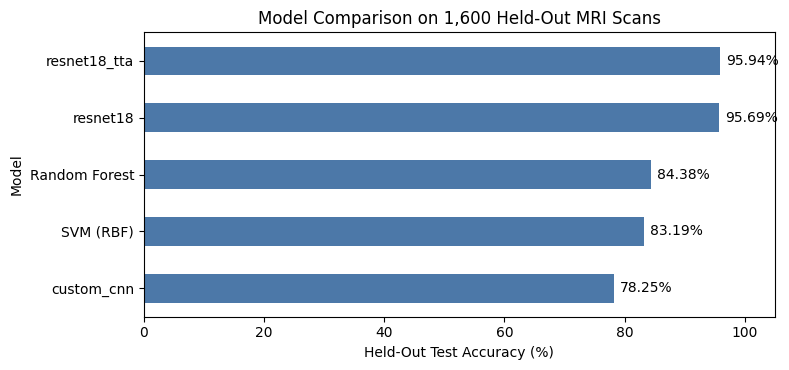

In [5]:
rows = []
ml_report = REPORTS_DIR / "classical_ml_report.json"
if ml_report.exists():
    for name, metrics in json.loads(ml_report.read_text(encoding="utf-8")).items():
        macro = metrics["classification_report"]["macro avg"]
        rows.append({"Model": name, "Accuracy (%)": metrics["accuracy"] * 100, "Macro F1": macro["f1-score"]})

for p in sorted(REPORTS_DIR.glob("*_report.json")):
    if p.name == "classical_ml_report.json":
        continue
    data = json.loads(p.read_text(encoding="utf-8"))
    rep = data["classification_report"]
    rows.append({"Model": data.get("model", p.stem), "Accuracy (%)": rep["accuracy"] * 100, "Macro F1": rep["macro avg"]["f1-score"]})

df = pd.DataFrame(rows).sort_values("Accuracy (%)", ascending=True)
display(df)

if not df.empty:
    ax = df.plot.barh(x="Model", y="Accuracy (%)", legend=False, figsize=(8, 3.8), color="#4C78A8")
    ax.set_xlim(0, 105)
    ax.set_xlabel("Held-Out Test Accuracy (%)")
    ax.set_title("Model Comparison on 1,600 Held-Out MRI Scans")
    for bar in ax.patches:
        ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"{bar.get_width():.2f}%", va="center")
    plt.tight_layout()
    plt.show()